# Chapter 5 Capstone — Monte Carlo Pricing and Static Hedging in a Large State Space

## Financial Question

How accurately can a large simulated static economy price and hedge a European call option, and how do pricing uncertainty and hedging error change when market volatility is stressed?

This notebook builds a reusable Monte Carlo pricing sandbox based on the Chapter 5 static-economy framework.

The analysis has four objectives:

1. simulate a large finite state space for a stock under the Black–Scholes–Merton model;
2. estimate a European call price and quantify Monte Carlo uncertainty with a confidence interval;
3. construct a least-squares static hedge using a bond and the stock and analyze its residual distribution;
4. compare pricing and hedging behavior across low-, baseline-, and high-volatility scenarios.

The baseline market parameters are

$$
S_0=100,
\qquad
K=105,
\qquad
r=5\%,
\qquad
\sigma=20\%,
\qquad
T=1.
$$

Under the risk-neutral measure, the terminal stock price is

$$
S_T
=
S_0
\exp\left[
\left(r-\frac{1}{2}\sigma^2\right)T
+
\sigma\sqrt{T}Z
\right],
\qquad
Z\sim N(0,1).
$$

The European call payoff is

$$
C_T=(S_T-K)^+.
$$

Its Monte Carlo price estimate is

$$
\boxed{
\hat C_0
=
e^{-rT}
\frac{1}{I}
\sum_{i=1}^{I}
C_T^{(i)}.
}
$$

The simulated terminal values can be interpreted as a large but finite state space, so the model remains static: only today and maturity matter.

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numpy.random import default_rng
from scipy.stats import norm

np.set_printoptions(
    precision=5,
    suppress=True,
)

S0 = 100.0
K = 105.0
r = 0.05
sigma = 0.20
T = 1.0

I = 50_000
seed = 100

print("S0:", S0)
print("K:", K)
print("r:", r)
print("sigma:", sigma)
print("T:", T)
print("Monte Carlo states:", I)
print("seed:", seed)

S0: 100.0
K: 105.0
r: 0.05
sigma: 0.2
T: 1.0
Monte Carlo states: 50000
seed: 100


## 1. Baseline Monte Carlo Pricing

The baseline model uses risk-neutral geometric Brownian motion:

$$
S_T
=
S_0
\exp\left[
\left(r-\frac12\sigma^2\right)T
+
\sigma\sqrt{T}Z
\right],
\qquad
Z\sim N(0,1).
$$

For each simulated terminal stock value, the European call payoff is

$$
C_T=(S_T-K)^+.
$$

Discounting each payoff to time zero gives

$$
X_i=e^{-rT}C_T^{(i)}.
$$

The Monte Carlo option-price estimator is

$$
\boxed{
\hat C_0
=
\frac1I
\sum_{i=1}^{I}X_i.
}
$$

Because Monte Carlo pricing uses a finite random sample, the estimate has sampling uncertainty.

If $s_X$ is the sample standard deviation of the discounted payoffs, the estimated standard error of the Monte Carlo mean is

$$
\boxed{
SE(\hat C_0)
=
\frac{s_X}{\sqrt I}.
}
$$

Using a large-sample normal approximation, an approximate 95% confidence interval is

$$
\boxed{
\hat C_0
\pm
z_{0.975}SE(\hat C_0),
}
$$

where

$$
z_{0.975}\approx1.96.
$$

The confidence interval quantifies Monte Carlo sampling uncertainty inside the specified pricing model. It does not measure model risk or uncertainty about the model parameters themselves.

In [2]:
rng = default_rng(seed)

Z = rng.standard_normal(I)

ST = S0 * np.exp(
    (r - 0.5 * sigma ** 2) * T
    + sigma * math.sqrt(T) * Z
)

CT = np.maximum(
    ST - K,
    0.0,
)

discount_factor = math.exp(-r * T)

discounted_payoffs = (
    discount_factor * CT
)

mc_price = float(
    np.mean(discounted_payoffs)
)

payoff_sd = float(
    np.std(
        discounted_payoffs,
        ddof=1,
    )
)

mc_se = payoff_sd / math.sqrt(I)

z_95 = float(
    norm.ppf(0.975)
)

ci_low = mc_price - z_95 * mc_se
ci_high = mc_price + z_95 * mc_se

print("Monte Carlo price:", mc_price)
print("Discounted-payoff SD:", payoff_sd)
print("Monte Carlo SE:", mc_se)
print("95% CI lower:", ci_low)
print("95% CI upper:", ci_high)

Monte Carlo price: 8.113083310449477
Discounted-payoff SD: 13.218567399097472
Monte Carlo SE: 0.05911523053908908
95% CI lower: 7.9972195876550805
95% CI upper: 8.228947033243875


### Analytical Benchmark

The Monte Carlo estimator can be compared with the analytical Black–Scholes value for a European call.

For a non-dividend-paying stock,

$$
C_0^{BS}
=
S_0N(d_1)
-
Ke^{-rT}N(d_2),
$$

where

$$
d_1
=
\frac{
\ln(S_0/K)
+
\left(r+\frac12\sigma^2\right)T
}{
\sigma\sqrt T
},
$$

and

$$
d_2=d_1-\sigma\sqrt T.
$$

The analytical value provides a benchmark for assessing Monte Carlo sampling error.

A successful Monte Carlo estimate need not equal the analytical price exactly. Because the estimate is based on a finite random sample, sampling variation remains.

A useful diagnostic is whether the analytical benchmark lies inside the Monte Carlo confidence interval.

In [3]:
d1 = (
    math.log(S0 / K)
    + (r + 0.5 * sigma ** 2) * T
) / (
    sigma * math.sqrt(T)
)

d2 = (
    d1
    - sigma * math.sqrt(T)
)

bs_price = (
    S0 * norm.cdf(d1)
    - K * math.exp(-r * T) * norm.cdf(d2)
)

abs_error = abs(
    mc_price - bs_price
)

abs_relative_error = (
    abs_error / bs_price
)

benchmark_in_ci = (
    ci_low
    <= bs_price
    <= ci_high
)

baseline_summary = pd.DataFrame(
    {
        "Metric": [
            "Monte Carlo price",
            "Black-Scholes benchmark",
            "Monte Carlo SE",
            "95% CI lower",
            "95% CI upper",
            "Absolute error",
            "Absolute relative error",
        ],
        "Value": [
            mc_price,
            bs_price,
            mc_se,
            ci_low,
            ci_high,
            abs_error,
            abs_relative_error,
        ],
    }
)

print(
    "Black-Scholes benchmark:",
    bs_price,
)
print(
    "Benchmark inside 95% CI:",
    benchmark_in_ci,
)

baseline_summary

Black-Scholes benchmark: 8.021352235143176
Benchmark inside 95% CI: True


,Metric,Value
0,Monte Carlo price,8.113083
1,Black-Scholes benchmark,8.021352
2,Monte Carlo SE,0.059115
3,95% CI lower,7.997220
4,95% CI upper,8.228947
5,Absolute error,0.091731
6,Absolute relative error,0.011436


## 2. Pricing Diagnostics

A Monte Carlo price should be accompanied by diagnostics showing the simulated state space that generated the estimate.

The first diagnostic examines the terminal stock-price distribution.

Under risk-neutral geometric Brownian motion,

$$
S_T
=
S_0
\exp\left[
\left(r-\frac12\sigma^2\right)T
+
\sigma\sqrt{T}Z
\right].
$$

Therefore $S_T$ is lognormally distributed.

Its theoretical risk-neutral expectation is

$$
\boxed{
\mathbb E_Q[S_T]
=
S_0e^{rT}.
}
$$

The simulated distribution should therefore have:

- strictly positive terminal prices;
- a right-skewed shape;
- a simulated mean reasonably close to $S_0e^{rT}$.

This plot provides a visual check that the Monte Carlo state space behaves consistently with the assumed pricing model.

Simulated E[ST]: 105.31271091314686
Theoretical E[ST]: 105.12710963760242
ST standard deviation: 21.229036675293383


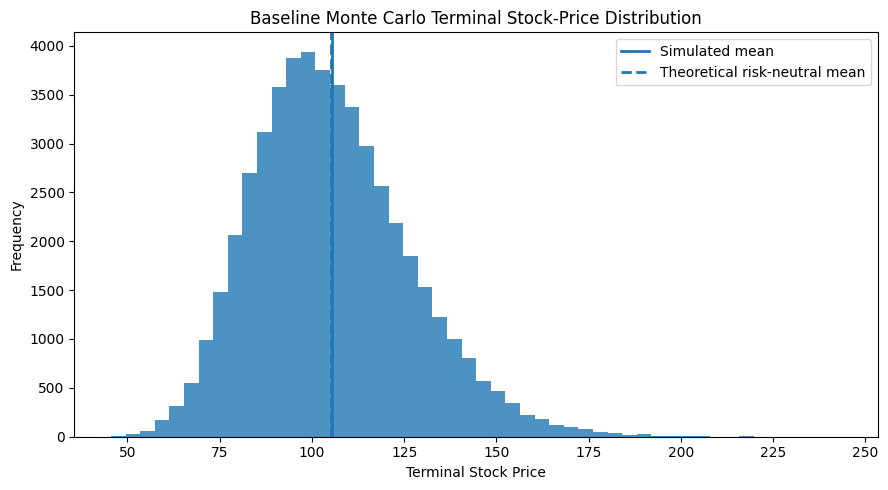

In [4]:
simulated_ST_mean = float(
    np.mean(ST)
)

theoretical_ST_mean = (
    S0 * math.exp(r * T)
)

simulated_ST_sd = float(
    np.std(ST)
)

print(
    "Simulated E[ST]:",
    simulated_ST_mean,
)

print(
    "Theoretical E[ST]:",
    theoretical_ST_mean,
)

print(
    "ST standard deviation:",
    simulated_ST_sd,
)

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    ST,
    bins=50,
    alpha=0.80,
)

plt.axvline(
    simulated_ST_mean,
    linewidth=2,
    label="Simulated mean",
)

plt.axvline(
    theoretical_ST_mean,
    linestyle="--",
    linewidth=2,
    label="Theoretical risk-neutral mean",
)

plt.xlabel("Terminal Stock Price")
plt.ylabel("Frequency")
plt.title(
    "Baseline Monte Carlo Terminal Stock-Price Distribution"
)

plt.legend()
plt.tight_layout()
plt.show()

### Discounted Payoff Distribution

The Monte Carlo price is the sample mean of the discounted option payoffs,

$$
X_i
=
e^{-rT}(S_T^{(i)}-K)^+.
$$

Unlike the terminal stock-price distribution, the call-payoff distribution contains a point mass at zero.

Whenever

$$
S_T\le K,
$$

the option expires out of the money and

$$
C_T=0.
$$

For states in which

$$
S_T>K,
$$

the payoff increases linearly with the terminal stock price.

Therefore the discounted-payoff distribution is expected to be highly right-skewed:

- many simulated states produce zero payoff;
- positive payoffs occur only in in-the-money states;
- unusually high terminal stock prices generate a long positive tail.

The dispersion of these discounted payoffs determines the Monte Carlo standard error,

$$
SE(\hat C_0)
=
\frac{s_X}{\sqrt I}.
$$

This links the payoff distribution directly to the statistical precision of the price estimate.

In-the-money fraction: 0.46624
Zero-payoff fraction: 0.53376
Mean discounted payoff | ITM: 17.401088088644208


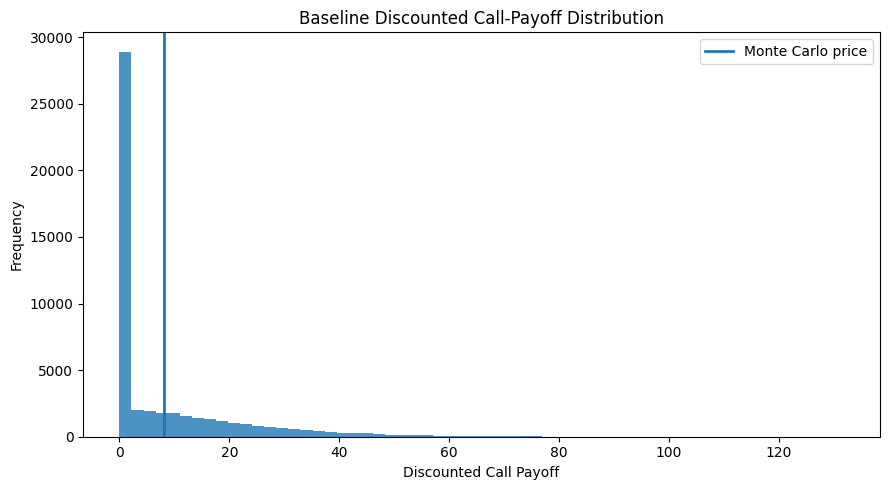

In [5]:
in_the_money = CT > 0.0

itm_probability = float(
    np.mean(in_the_money)
)

zero_payoff_probability = float(
    np.mean(~in_the_money)
)

mean_positive_payoff = float(
    np.mean(
        discounted_payoffs[in_the_money]
    )
)

print(
    "In-the-money fraction:",
    itm_probability,
)

print(
    "Zero-payoff fraction:",
    zero_payoff_probability,
)

print(
    "Mean discounted payoff | ITM:",
    mean_positive_payoff,
)

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    discounted_payoffs,
    bins=60,
    alpha=0.80,
)

plt.axvline(
    mc_price,
    linewidth=2,
    label="Monte Carlo price",
)

plt.xlabel("Discounted Call Payoff")
plt.ylabel("Frequency")
plt.title(
    "Baseline Discounted Call-Payoff Distribution"
)

plt.legend()
plt.tight_layout()
plt.show()

## 3. Reusable Monte Carlo Pricing Sandbox

The direct baseline calculation can now be consolidated into a reusable pricing function.

For a chosen set of market parameters, the function:

1. simulates terminal stock prices under risk-neutral geometric Brownian motion;
2. calculates European call payoffs;
3. discounts the payoffs to time zero;
4. estimates the option price;
5. calculates the Monte Carlo standard error;
6. constructs a confidence interval;
7. records useful diagnostics such as the in-the-money fraction;
8. optionally produces terminal-price and discounted-payoff plots.

The function preserves a fixed random seed when requested so that results are reproducible.

In [6]:
def mc_call_pricer(
    S0,
    K,
    r,
    sigma,
    T,
    I=50_000,
    seed=100,
    confidence=0.95,
    make_plots=True,
):
    """Monte Carlo pricer for a European call under risk-neutral GBM."""

    rng = default_rng(seed)

    Z = rng.standard_normal(I)

    ST = S0 * np.exp(
        (r - 0.5 * sigma ** 2) * T
        + sigma * math.sqrt(T) * Z
    )

    CT = np.maximum(
        ST - K,
        0.0,
    )

    discount_factor = math.exp(
        -r * T
    )

    discounted_payoffs = (
        discount_factor * CT
    )

    price = float(
        np.mean(discounted_payoffs)
    )

    payoff_sd = float(
        np.std(
            discounted_payoffs,
            ddof=1,
        )
    )

    se = payoff_sd / math.sqrt(I)

    alpha = 1.0 - confidence

    z_value = float(
        norm.ppf(
            1.0 - alpha / 2.0
        )
    )

    ci_low = price - z_value * se
    ci_high = price + z_value * se

    itm_fraction = float(
        np.mean(CT > 0.0)
    )

    figures = []

    if make_plots:
        fig1, ax1 = plt.subplots(
            figsize=(9, 5)
        )

        ax1.hist(
            ST,
            bins=50,
            alpha=0.80,
        )

        ax1.axvline(
            np.mean(ST),
            linewidth=2,
            label="Simulated mean",
        )

        ax1.set_xlabel(
            "Terminal Stock Price"
        )

        ax1.set_ylabel(
            "Frequency"
        )

        ax1.set_title(
            "Terminal Stock-Price Distribution"
        )

        ax1.legend()
        fig1.tight_layout()

        figures.append(fig1)

        fig2, ax2 = plt.subplots(
            figsize=(9, 5)
        )

        ax2.hist(
            discounted_payoffs,
            bins=60,
            alpha=0.80,
        )

        ax2.axvline(
            price,
            linewidth=2,
            label="Monte Carlo price",
        )

        ax2.set_xlabel(
            "Discounted Call Payoff"
        )

        ax2.set_ylabel(
            "Frequency"
        )

        ax2.set_title(
            "Discounted Call-Payoff Distribution"
        )

        ax2.legend()
        fig2.tight_layout()

        figures.append(fig2)

    return {
        "price": price,
        "se": se,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "confidence": confidence,
        "itm_fraction": itm_fraction,
        "ST": ST,
        "CT": CT,
        "discounted_payoffs": discounted_payoffs,
        "figures": figures,
    }

In [7]:
baseline_result = mc_call_pricer(
    S0=S0,
    K=K,
    r=r,
    sigma=sigma,
    T=T,
    I=I,
    seed=seed,
    confidence=0.95,
    make_plots=False,
)

print(
    "Function price:",
    baseline_result["price"],
)

print(
    "Direct price:",
    mc_price,
)

print(
    "Price matches:",
    np.isclose(
        baseline_result["price"],
        mc_price,
    ),
)

print(
    "CI matches:",
    (
        np.isclose(
            baseline_result["ci_low"],
            ci_low,
        )
        and np.isclose(
            baseline_result["ci_high"],
            ci_high,
        )
    ),
)

Function price: 8.113083310449477
Direct price: 8.113083310449477
Price matches: True
CI matches: True


## 4. Least-Squares Static Hedging

The Monte Carlo state space can also be used to study approximate replication.

Only two traded assets are used:

1. a risk-free bond;
2. the underlying stock.

The bond has current value

$$
B_0=100
$$

and terminal value

$$
B_T=B_0e^{rT}.
$$

Across the simulated states, the traded-payoff matrix is

$$
A=
\begin{pmatrix}
B_T & S_T^{(1)}\\
B_T & S_T^{(2)}\\
\vdots & \vdots\\
B_T & S_T^{(I)}
\end{pmatrix}.
$$

The static hedge chooses bond and stock holdings

$$
\phi=
\begin{pmatrix}
\phi_B\\
\phi_S
\end{pmatrix}
$$

to minimize the squared difference between the portfolio payoff and the option payoff:

$$
\boxed{
\hat\phi
=
\arg\min_\phi
\|A\phi-C_T\|_2^2.
}
$$

The fitted option payoff is

$$
\hat C_T=A\hat\phi,
$$

and the replication error in state $i$ is

$$
e_i
=
\hat C_T^{(i)}
-
C_T^{(i)}.
$$

A positive residual means the hedge over-replicates the option in that state, while a negative residual means it under-replicates it.

The root mean squared error is

$$
\boxed{\mathrm{RMSE}
=
\left(\frac{1}{I}\sum_{i=1}^{I} e_i^2\right)^{1/2}}
$$

This is a static approximation. It should not be confused with the dynamically rebalanced hedge used in the full Black–Scholes framework.

In [8]:
B0 = 100.0

BT = (
    B0
    * math.exp(r * T)
    * np.ones_like(ST)
)

A = np.column_stack(
    (
        BT,
        ST,
    )
)

phi = np.linalg.lstsq(
    A,
    CT,
    rcond=None,
)[0]

CT_hat = A @ phi

hedge_error = (
    CT_hat - CT
)

hedge_rmse = float(
    np.sqrt(
        np.mean(
            hedge_error ** 2
        )
    )
)

hedge_mae = float(
    np.mean(
        np.abs(hedge_error)
    )
)

mean_hedge_error = float(
    np.mean(hedge_error)
)

hedge_cost = float(
    np.dot(
        np.array([B0, S0]),
        phi,
    )
)

print("Hedge phi:", phi)
print("Hedge cost:", hedge_cost)
print("RMSE:", hedge_rmse)
print("MAE:", hedge_mae)
print("Mean residual:", mean_hedge_error)

Hedge phi: [-0.50387  0.58397]
Hedge cost: 8.009983027384337
RMSE: 6.277933412490137
MAE: 5.042715057400708
Mean residual: -3.4935396797663996e-14


### Static Hedge Residual Diagnostics

The least-squares hedge minimizes total squared terminal replication error, but it does not eliminate state-by-state mismatch.

The residual in state $i$ is

$$
e_i
=
\hat C_T^{(i)}
-
C_T^{(i)}.
$$

Therefore:

- $e_i>0$ means the hedge over-replicates the call payoff;
- $e_i<0$ means the hedge under-replicates the call payoff.

The mean residual is approximately zero because the regression includes the constant-payoff bond. This does not imply that the hedge is accurate in every state.

The residual distribution reveals features that RMSE and MAE alone cannot show, including:

- skewness;
- tail behavior;
- concentration of small errors;
- rare but economically important large hedging errors.

This is especially relevant for a convex option payoff, because a static linear combination of bond and stock cannot reproduce the call's kink exactly across all simulated states.

Residual SD: 6.277996192765968
Minimum residual: -49.29722772981165
Maximum residual: 8.345199127879226


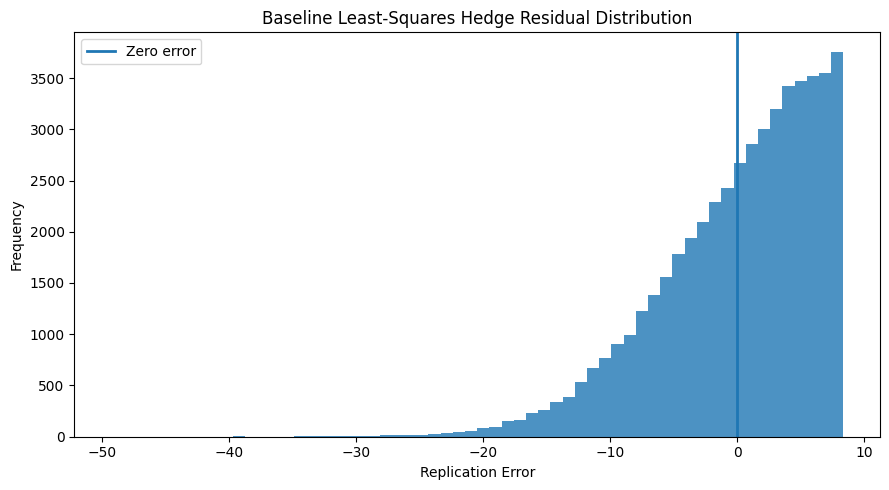

In [9]:
residual_sd = float(
    np.std(
        hedge_error,
        ddof=1,
    )
)

residual_min = float(
    np.min(hedge_error)
)

residual_max = float(
    np.max(hedge_error)
)

print(
    "Residual SD:",
    residual_sd,
)

print(
    "Minimum residual:",
    residual_min,
)

print(
    "Maximum residual:",
    residual_max,
)

plt.figure(
    figsize=(9, 5)
)

plt.hist(
    hedge_error,
    bins=60,
    alpha=0.80,
)

plt.axvline(
    0.0,
    linewidth=2,
    label="Zero error",
)

plt.xlabel(
    "Replication Error"
)

plt.ylabel(
    "Frequency"
)

plt.title(
    "Baseline Least-Squares Hedge Residual Distribution"
)

plt.legend()
plt.tight_layout()
plt.show()

## 5. Reusable Static Hedging Module

The direct least-squares calculation can now be packaged into a reusable hedging function.

For a simulated terminal stock-price vector $S_T$ and option payoff vector $C_T$, the function:

1. constructs the terminal bond payoff;
2. builds the traded-payoff matrix from bond and stock;
3. solves the least-squares replication problem;
4. computes the fitted claim payoff;
5. calculates state-by-state residuals;
6. reports RMSE, MAE, mean residual, and hedge cost.

The optimization problem is

$$
\boxed{
\hat\phi
=
\arg\min_\phi
\|A\phi-C_T\|_2^2.
}
$$

The module will later be reused without modification across volatility stress scenarios.

In [10]:
def static_call_hedge(
    ST,
    CT,
    S0,
    r,
    T,
    B0=100.0,
):
    """Least-squares static hedge using a bond and stock."""

    BT = (
        B0
        * math.exp(r * T)
        * np.ones_like(ST)
    )

    A = np.column_stack(
        (
            BT,
            ST,
        )
    )

    phi = np.linalg.lstsq(
        A,
        CT,
        rcond=None,
    )[0]

    fitted_payoff = A @ phi

    residuals = (
        fitted_payoff - CT
    )

    rmse = float(
        np.sqrt(
            np.mean(
                residuals ** 2
            )
        )
    )

    mae = float(
        np.mean(
            np.abs(residuals)
        )
    )

    mean_residual = float(
        np.mean(residuals)
    )

    hedge_cost = float(
        np.dot(
            np.array([B0, S0]),
            phi,
        )
    )

    return {
        "phi": phi,
        "hedge_cost": hedge_cost,
        "rmse": rmse,
        "mae": mae,
        "mean_residual": mean_residual,
        "fitted_payoff": fitted_payoff,
        "residuals": residuals,
        "A": A,
    }

In [11]:
baseline_hedge = static_call_hedge(
    ST=ST,
    CT=CT,
    S0=S0,
    r=r,
    T=T,
    B0=B0,
)

print(
    "Function phi:",
    baseline_hedge["phi"],
)

print(
    "Direct phi:",
    phi,
)

print(
    "Phi matches:",
    np.allclose(
        baseline_hedge["phi"],
        phi,
    ),
)

print(
    "RMSE matches:",
    np.isclose(
        baseline_hedge["rmse"],
        hedge_rmse,
    ),
)

print(
    "Hedge cost matches:",
    np.isclose(
        baseline_hedge["hedge_cost"],
        hedge_cost,
    ),
)

Function phi: [-0.50387  0.58397]
Direct phi: [-0.50387  0.58397]
Phi matches: True
RMSE matches: True
Hedge cost matches: True


## 6. Volatility Stress Scenarios

The capstone stress test changes the volatility parameter while holding the remaining market assumptions fixed.

Three scenarios are considered:

$$
\sigma_{\text{low}}=15\%,
$$

$$
\sigma_{\text{base}}=20\%,
$$

and

$$
\sigma_{\text{high}}=30\%.
$$

For each volatility level, the analysis recomputes:

- the Monte Carlo option price;
- the 95% confidence interval;
- the analytical Black-Scholes benchmark;
- the in-the-money fraction;
- the least-squares hedge positions;
- the static hedge cost;
- RMSE;
- MAE.

The same random seed and number of simulated states are used in every scenario.

This creates common random numbers across scenarios, reducing irrelevant simulation noise in the comparison and making the effect of changing volatility easier to interpret.

Economically, higher volatility increases the dispersion of terminal stock prices.

Because a European call has the convex payoff

$$
C_T=(S_T-K)^+,
$$

greater dispersion can increase option value even when the risk-neutral expected stock price remains tied to

$$
\mathbb E_Q[S_T]=S_0e^{rT}.
$$

The stress test also asks whether a single static bond-stock hedge becomes more or less accurate as the distribution of terminal outcomes widens.

In [12]:
def bs_call_price(
    S0,
    K,
    r,
    sigma,
    T,
):
    """Analytical Black-Scholes European call price."""

    d1 = (
        math.log(S0 / K)
        + (r + 0.5 * sigma ** 2) * T
    ) / (
        sigma * math.sqrt(T)
    )

    d2 = (
        d1
        - sigma * math.sqrt(T)
    )

    return float(
        S0 * norm.cdf(d1)
        - K
        * math.exp(-r * T)
        * norm.cdf(d2)
    )

In [13]:
volatility_scenarios = {
    "Low volatility": 0.15,
    "Baseline": 0.20,
    "High volatility": 0.30,
}

stress_rows = []

stress_results = {}

for scenario, sigma_value in volatility_scenarios.items():

    pricing = mc_call_pricer(
        S0=S0,
        K=K,
        r=r,
        sigma=sigma_value,
        T=T,
        I=I,
        seed=seed,
        confidence=0.95,
        make_plots=False,
    )

    hedge = static_call_hedge(
        ST=pricing["ST"],
        CT=pricing["CT"],
        S0=S0,
        r=r,
        T=T,
        B0=B0,
    )

    benchmark = bs_call_price(
        S0=S0,
        K=K,
        r=r,
        sigma=sigma_value,
        T=T,
    )

    stress_results[scenario] = {
        "pricing": pricing,
        "hedge": hedge,
        "benchmark": benchmark,
    }

    stress_rows.append(
        {
            "Scenario": scenario,
            "Volatility": sigma_value,
            "MC Price": pricing["price"],
            "BS Benchmark": benchmark,
            "CI Lower": pricing["ci_low"],
            "CI Upper": pricing["ci_high"],
            "ITM Fraction": pricing["itm_fraction"],
            "Bond Holding": hedge["phi"][0],
            "Stock Holding": hedge["phi"][1],
            "Hedge Cost": hedge["hedge_cost"],
            "RMSE": hedge["rmse"],
            "MAE": hedge["mae"],
        }
    )

stress_table = pd.DataFrame(
    stress_rows
)

stress_table

,Scenario,Volatility,MC Price,BS Benchmark,CI Lower,CI Upper,ITM Fraction,Bond Holding,Stock Holding,Hedge Cost,RMSE,MAE
0,Low volatility,0.15,6.104040,6.035564,6.019602,6.188477,0.47684,-0.504977,0.565262,6.028540,4.720106,3.787110
1,Baseline,0.20,8.113083,8.021352,7.997220,8.228947,0.46624,-0.503874,0.583974,8.009983,6.277933,5.042715
2,High volatility,0.30,12.115462,11.976881,11.931011,12.299913,0.44474,-0.502073,0.621616,11.954311,9.354247,7.538034


### Stress-Test Interpretation

The volatility stress experiment produces two main effects.

First, the European call becomes more valuable as volatility rises.

This reflects the convex payoff

$$
C_T=(S_T-K)^+.
$$

Greater dispersion creates more extreme upside states while the option payoff remains bounded below by zero.

Interestingly, the fraction of states in which the option finishes in the money decreases across the three scenarios. This does not conflict with the increase in option value: higher volatility produces a more dispersed distribution, so fewer but larger positive payoffs can increase the expected option payoff.

Second, the static least-squares hedge becomes less accurate as volatility rises.

Both RMSE and MAE increase substantially across the stress scenarios:

$$
\text{higher volatility}
\rightarrow
\text{greater terminal-payoff dispersion}
\rightarrow
\text{larger static replication errors}.
$$

The fitted stock holding also rises with volatility, indicating that the least-squares hedge requires greater exposure to the underlying stock as the option becomes more sensitive to large upside outcomes.

These results apply to the one-period static hedge studied here. They should not be interpreted as the performance of a dynamically rebalanced Black–Scholes hedge.

In [14]:
stress_display = stress_table.copy()

stress_display["Volatility"] = (
    stress_display["Volatility"]
    .map(lambda x: f"{x:.0%}")
)

stress_display["MC Price"] = (
    stress_display["MC Price"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["BS Benchmark"] = (
    stress_display["BS Benchmark"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["CI Lower"] = (
    stress_display["CI Lower"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["CI Upper"] = (
    stress_display["CI Upper"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["ITM Fraction"] = (
    stress_display["ITM Fraction"]
    .map(lambda x: f"{x:.2%}")
)

stress_display["Bond Holding"] = (
    stress_display["Bond Holding"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["Stock Holding"] = (
    stress_display["Stock Holding"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["Hedge Cost"] = (
    stress_display["Hedge Cost"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["RMSE"] = (
    stress_display["RMSE"]
    .map(lambda x: f"{x:.4f}")
)

stress_display["MAE"] = (
    stress_display["MAE"]
    .map(lambda x: f"{x:.4f}")
)

stress_display

,Scenario,Volatility,MC Price,BS Benchmark,CI Lower,CI Upper,ITM Fraction,Bond Holding,Stock Holding,Hedge Cost,RMSE,MAE
0,Low volatility,15%,6.1040,6.0356,6.0196,6.1885,47.68%,-0.5050,0.5653,6.0285,4.7201,3.7871
1,Baseline,20%,8.1131,8.0214,7.9972,8.2289,46.62%,-0.5039,0.5840,8.0100,6.2779,5.0427
2,High volatility,30%,12.1155,11.9769,11.9310,12.2999,44.47%,-0.5021,0.6216,11.9543,9.3542,7.5380


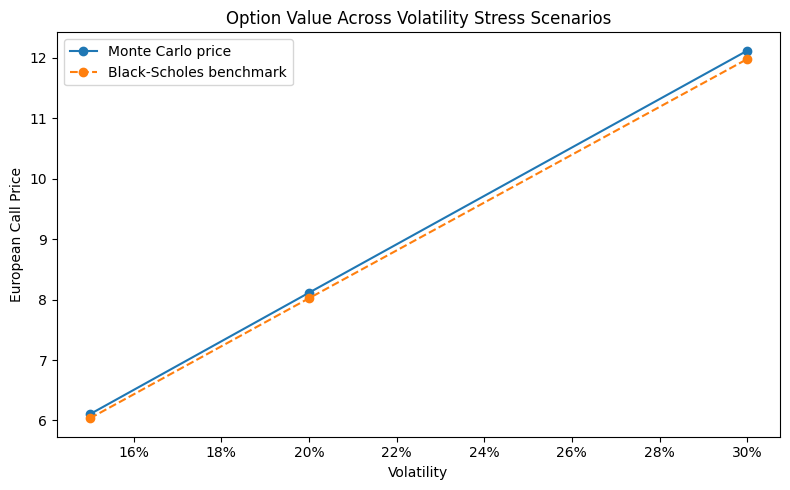

In [15]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    stress_table["Volatility"],
    stress_table["MC Price"],
    marker="o",
    label="Monte Carlo price",
)

plt.plot(
    stress_table["Volatility"],
    stress_table["BS Benchmark"],
    marker="o",
    linestyle="--",
    label="Black-Scholes benchmark",
)

plt.xlabel("Volatility")
plt.ylabel("European Call Price")
plt.title(
    "Option Value Across Volatility Stress Scenarios"
)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.0%}"
    )
)

plt.legend()
plt.tight_layout()
plt.show()

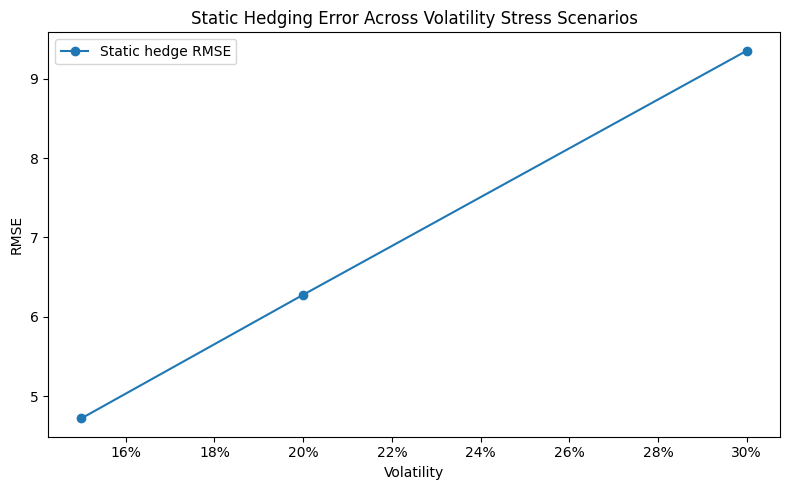

In [16]:
plt.figure(
    figsize=(8, 5)
)

plt.plot(
    stress_table["Volatility"],
    stress_table["RMSE"],
    marker="o",
    label="Static hedge RMSE",
)

plt.xlabel("Volatility")
plt.ylabel("RMSE")
plt.title(
    "Static Hedging Error Across Volatility Stress Scenarios"
)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(
        lambda x, _: f"{x:.0%}"
    )
)

plt.legend()
plt.tight_layout()
plt.show()

## 7. Conclusions and Model Limitations

### Conclusions

This capstone turned the Chapter 5 large-static-economy framework into a reusable Monte Carlo pricing and hedging sandbox.

The baseline Black–Scholes–Merton simulation used

$$
S_0=100,
\qquad
K=105,
\qquad
r=5\%,
\qquad
\sigma=20\%,
\qquad
T=1,
$$

with

$$
I=50{,}000
$$

simulated terminal states.

The baseline Monte Carlo call-price estimate was approximately

$$
\boxed{
\hat C_0=8.1131.
}
$$

The estimated Monte Carlo standard error was approximately

$$
0.0591,
$$

producing an approximate 95% confidence interval of

$$
\boxed{
[7.9972,\;8.2289].
}
$$

The analytical Black–Scholes benchmark was approximately

$$
\boxed{
C_0^{BS}=8.0214,
}
$$

which lies inside the Monte Carlo confidence interval.

This supports the interpretation that the difference between the analytical and simulated prices is consistent with finite-sample Monte Carlo error rather than a disagreement between the pricing methods.

The simulated terminal stock prices also passed a model-level diagnostic: their mean was close to the theoretical risk-neutral expectation

$$
\mathbb E_Q[S_T]=S_0e^{rT}.
$$

The discounted call-payoff distribution was highly right-skewed. More than half of the simulated states produced zero option payoff, while relatively fewer in-the-money states generated a long positive payoff tail.

### Static Hedging

A least-squares static hedge using the bond and stock produced approximately

$$
\boxed{
\phi=
(-0.5039,\;0.5840).
}
$$

The hedge cost was approximately

$$
8.0100.
$$

The baseline residual diagnostics were

$$
RMSE\approx6.2779,
$$

and

$$
MAE\approx5.0427.
$$

The mean residual was numerically zero, but the residual distribution was strongly left-skewed, with a minimum error near

$$
-49.30.
$$

This illustrates an important distinction:

$$
\boxed{
\text{zero average residual}
\neq
\text{small state-by-state hedging risk}.
}
$$

A static linear bond-stock payoff cannot exactly reproduce the convex European call payoff over all simulated states.

### Volatility Stress Test

Three volatility environments were compared:

$$
15\%,\qquad20\%,\qquad30\%.
$$

As volatility increased, the Monte Carlo call price rose from approximately

$$
6.10
$$

to

$$
8.11
$$

to

$$
12.12.
$$

This reflects the convexity of the call payoff: greater terminal-price dispersion increases the value of extreme upside outcomes while the payoff remains bounded below by zero.

At the same time, the static hedge became less accurate:

$$
RMSE:
\quad
4.72
\rightarrow
6.28
\rightarrow
9.35.
$$

The stock holding in the least-squares hedge also increased as volatility rose.

The combined result is

$$
\boxed{
\text{higher volatility}
\rightarrow
\text{higher option value}
\quad\text{and}\quad
\text{larger static hedging error}.
}
$$

### Model Limitations

The numerical results should be interpreted within the deliberately simplified model used in this notebook.

In particular:

- terminal stock prices follow risk-neutral geometric Brownian motion;
- volatility, the short rate, and maturity are fixed;
- no dividends are modeled;
- transaction costs, liquidity constraints, and bid-ask spreads are ignored;
- the Monte Carlo confidence interval measures simulation uncertainty, not model uncertainty;
- the hedge is static and remains unchanged between time zero and maturity;
- the static least-squares hedge is not the continuously rebalanced Black–Scholes delta hedge;
- volatility stresses are scenario assumptions rather than forecasts;
- common random numbers improve scenario comparability but do not remove model risk.

The exercise therefore demonstrates a reusable computational framework rather than an empirical trading or hedging strategy.

The central Chapter 5 workflow is

$$
\boxed{
\text{large state space}
\rightarrow
\text{Monte Carlo pricing}
\rightarrow
\text{sampling uncertainty}
\rightarrow
\text{approximate replication}
\rightarrow
\text{residual risk}
\rightarrow
\text{stress testing}.
}
$$

## 8. Reproducibility and Validation

The final validation block checks the principal relationships used throughout the notebook.

The tests verify that:

1. all primitive market inputs are admissible;
2. the direct Monte Carlo calculation matches the reusable pricing function;
3. the baseline analytical Black–Scholes value lies inside the 95% Monte Carlo confidence interval;
4. the simulated risk-neutral terminal-stock mean is reasonably close to $S_0e^{rT}$;
5. the direct least-squares hedge matches the reusable hedging function;
6. the least-squares mean residual is numerically zero;
7. each stress-scenario Black–Scholes benchmark lies inside its Monte Carlo confidence interval;
8. option value rises across the chosen volatility stress scenarios;
9. static hedge RMSE rises across the chosen volatility stress scenarios;
10. all stress scenarios use the same number of simulated states.

These tests separate successful code execution from internal financial and numerical consistency.

In [17]:
checks = {}

checks["positive_spot"] = (
    S0 > 0
)

checks["positive_strike"] = (
    K > 0
)

checks["positive_volatility"] = (
    sigma > 0
)

checks["positive_maturity"] = (
    T > 0
)

checks["valid_simulation_size"] = (
    I > 1
)

checks["pricing_function_matches_direct"] = np.isclose(
    baseline_result["price"],
    mc_price,
)

checks["baseline_ci_matches_direct"] = (
    np.isclose(
        baseline_result["ci_low"],
        ci_low,
    )
    and np.isclose(
        baseline_result["ci_high"],
        ci_high,
    )
)

checks["bs_benchmark_inside_baseline_ci"] = (
    ci_low
    <= bs_price
    <= ci_high
)

checks["risk_neutral_stock_mean"] = np.isclose(
    simulated_ST_mean,
    theoretical_ST_mean,
    rtol=0.01,
)

checks["hedge_function_matches_direct"] = np.allclose(
    baseline_hedge["phi"],
    phi,
)

checks["hedge_rmse_matches_direct"] = np.isclose(
    baseline_hedge["rmse"],
    hedge_rmse,
)

checks["mean_residual_near_zero"] = np.isclose(
    baseline_hedge["mean_residual"],
    0.0,
    atol=1e-10,
)

benchmarks_inside_ci = []

for _, row in stress_table.iterrows():
    benchmarks_inside_ci.append(
        row["CI Lower"]
        <= row["BS Benchmark"]
        <= row["CI Upper"]
    )

checks["all_stress_benchmarks_inside_ci"] = all(
    benchmarks_inside_ci
)

mc_prices = stress_table[
    "MC Price"
].to_numpy()

checks["mc_price_rises_with_volatility"] = np.all(
    np.diff(mc_prices) > 0
)

hedge_rmses = stress_table[
    "RMSE"
].to_numpy()

checks["rmse_rises_with_volatility"] = np.all(
    np.diff(hedge_rmses) > 0
)

checks["stress_scenario_count"] = (
    len(stress_table) == 3
)

for name, passed in checks.items():
    print(
        f"{name}: {passed}"
    )

assert all(
    checks.values()
)

print()
print(
    "All validation checks passed."
)

positive_spot: True
positive_strike: True
positive_volatility: True
positive_maturity: True
valid_simulation_size: True
pricing_function_matches_direct: True
baseline_ci_matches_direct: True
bs_benchmark_inside_baseline_ci: True
risk_neutral_stock_mean: True
hedge_function_matches_direct: True
hedge_rmse_matches_direct: True
mean_residual_near_zero: True
all_stress_benchmarks_inside_ci: True
mc_price_rises_with_volatility: True
rmse_rises_with_volatility: True
stress_scenario_count: True

All validation checks passed.
